In [ ]:
# Plotting all catchments in this folder
import numpy as np
import pandas as pd
import itertools

import pickle
import torch
import gc
import os

In [ ]:
# Load the new and current split dictionaries
# with open("/home/mokr/Reservoir_Modelling/Sample_Pairs/even_val_test_catchment_date_pairs_splits.pkl", "rb") as f:
#     new_pairs_splits = pickle.load(f)

# with open("/home/mokr/Reservoir_Modelling/Sample_Pairs/catchment_date_pairs_splits.pkl", "rb") as f:
#     old_pairs_splits = pickle.load(f)

# Load current T-V-T metadata
train_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/train_res_tensor_metadata.pt"
)
train_non_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/train_non_res_tensor_metadata.pt"
)

val_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/val_res_tensor_metadata.pt"
)
val_non_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/val_non_res_tensor_metadata.pt"
)
test_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/test_res_tensor_metadata.pt"
)
test_non_res_tensor_metadata = torch.load(
    "/perm/mokr/CamelsGB_V2/test_non_res_tensor_metadata.pt"
)

# # Load current Val and Test data pairs
# val_non_res_tensor_data = torch.load(
#     "/perm/mokr/CamelsGB_V2/val_non_res_tensor_data.pt"
# )
# val_res_tensor_data = torch.load("/perm/mokr/CamelsGB_V2/val_res_tensor_data.pt")
# test_non_res_tensor_data = torch.load(
#     "/perm/mokr/CamelsGB_V2/test_non_res_tensor_data.pt"
# )
# test_res_tensor_data = torch.load("/perm/mokr/CamelsGB_V2/test_res_tensor_data.pt")

In [ ]:
def get_gauge_date_set(splits_list):
    """Extract set of (gauge_id, date) tuples from splits list"""
    return {(str(entry["gauge_id"]), entry["init_date"]) for entry in splits_list}

# Get new validation and test sets from new splits
new_val_res_set = get_gauge_date_set(new_pairs_splits["reservoir_val"])
new_val_non_res_set = get_gauge_date_set(new_pairs_splits["non_reservoir_val"])
new_test_res_set = get_gauge_date_set(new_pairs_splits["reservoir_test"])
new_test_non_res_set = get_gauge_date_set(new_pairs_splits["non_reservoir_test"])


In [ ]:
def filter_by_gauge_date(metadata, tensor_data, gauge_date_set):
    """Filter metadata and tensor_data by (gauge_id, date) pairs"""
    indices_to_keep = []
    
    for i, (gauge_id, date) in enumerate(zip(metadata["gauge_id"], metadata["init_date"])):
        # Convert gauge_id to string
        metadata_gauge_str = str(gauge_id)
        
        # Convert date string to pandas Timestamp for comparison
        if isinstance(date, str):
            metadata_date = pd.Timestamp(date)
        else:
            metadata_date = date
            
        # Check if this (gauge_id, date) pair is in the set
        if (metadata_gauge_str, metadata_date) in gauge_date_set:
            indices_to_keep.append(i)
    
    print(f"Found {len(indices_to_keep)} matching indices out of {len(metadata['gauge_id'])} total")
    
    # Filter metadata
    filtered_metadata = {
        key: [metadata[key][i] for i in indices_to_keep]
        for key in metadata.keys()
    }
    
    # Filter tensor_data
    filtered_tensor_data = {
        key: [tensor_data[key][i] for i in indices_to_keep]
        for key in tensor_data.keys()
    }
    
    return filtered_metadata, filtered_tensor_data

In [55]:
# Process reservoir data first
print("Processing reservoir data...")
# Combine old val and test reservoir data
combined_res_metadata = {
    key: val_res_tensor_metadata[key] + test_res_tensor_metadata[key]
    for key in val_res_tensor_metadata.keys()
}
combined_res_data = {
    key: val_res_tensor_data[key] + test_res_tensor_data[key]
    for key in val_res_tensor_data.keys()
}

# Filter and save new validation reservoir data
new_val_res_metadata, new_val_res_data = filter_by_gauge_date(
    combined_res_metadata, combined_res_data, new_val_res_set
)
torch.save(new_val_res_metadata, "/perm/mokr/CamelsGB_V2/ScotlandPlus_val_res_tensor_metadata.pt")
torch.save(new_val_res_data, "/perm/mokr/CamelsGB_V2/ScotlandPlus_val_res_tensor_data.pt")
print(f"New val - Reservoir: {len(new_val_res_metadata['gauge_id'])} samples")

Processing reservoir data...
Found 167255 matching indices out of 379676 total
New val - Reservoir: 167255 samples


In [56]:
# Filter and save new test reservoir data
new_test_res_metadata, new_test_res_data = filter_by_gauge_date(
    combined_res_metadata, combined_res_data, new_test_res_set
)
torch.save(new_test_res_metadata, "/perm/mokr/CamelsGB_V2/ScotlandPlus_test_res_tensor_metadata.pt")
torch.save(new_test_res_data, "/perm/mokr/CamelsGB_V2/ScotlandPlus_test_res_tensor_data.pt")
print(f"New test - Reservoir: {len(new_test_res_metadata['gauge_id'])} samples")

# Clear combined and test reservoir data
del combined_res_metadata, combined_res_data
del new_test_res_metadata, new_test_res_data
del new_val_res_metadata, new_val_res_data

# Clear old reservoir data
del val_res_tensor_metadata, test_res_tensor_metadata
del val_res_tensor_data, test_res_tensor_data
gc.collect()

gc.collect()

# Process non-reservoir data
print("Processing non-reservoir data...")
# Combine old val and test non-reservoir data
combined_non_res_metadata = {
    key: val_non_res_tensor_metadata[key] + test_non_res_tensor_metadata[key]
    for key in val_non_res_tensor_metadata.keys()
}
combined_non_res_data = {
    key: val_non_res_tensor_data[key] + test_non_res_tensor_data[key]
    for key in val_non_res_tensor_data.keys()
}


# Filter and save new validation non-reservoir data
new_val_non_res_metadata, new_val_non_res_data = filter_by_gauge_date(
    combined_non_res_metadata, combined_non_res_data, new_val_non_res_set
)
torch.save(new_val_non_res_metadata, "/perm/mokr/CamelsGB_V2/ScotlandPlus_val_non_res_tensor_metadata.pt")
torch.save(new_val_non_res_data, "/perm/mokr/CamelsGB_V2/ScotlandPlus_val_non_res_tensor_data.pt")
print(f"New val - Non-Reservoir: {len(new_val_non_res_metadata['gauge_id'])} samples")

# Clear val non-reservoir data
del new_val_non_res_metadata, new_val_non_res_data
# Clear old non-reservoir data
del val_non_res_tensor_metadata, test_non_res_tensor_metadata
del val_non_res_tensor_data, test_non_res_tensor_data

gc.collect()

# Filter and save new test non-reservoir data
new_test_non_res_metadata, new_test_non_res_data = filter_by_gauge_date(
    combined_non_res_metadata, combined_non_res_data, new_test_non_res_set
)
torch.save(new_test_non_res_metadata, "/perm/mokr/CamelsGB_V2/ScotlandPlus_test_non_res_tensor_metadata.pt")
torch.save(new_test_non_res_data, "/perm/mokr/CamelsGB_V2/ScotlandPlus_test_non_res_tensor_data.pt")
print(f"New test - Non-Reservoir: {len(new_test_non_res_metadata['gauge_id'])} samples")

print("\nAll data processed and saved successfully!")

Found 212421 matching indices out of 379676 total
New test - Reservoir: 212421 samples
Processing non-reservoir data...
Found 167255 matching indices out of 379676 total
New val - Non-Reservoir: 167255 samples
Found 212421 matching indices out of 379676 total
New test - Non-Reservoir: 212421 samples

All data processed and saved successfully!


# Plot of Gauge Dates by latitude

In [28]:
folder_path = "/perm/mokr/CamelsGB_V2/Catchment_Attributes/"
All_Static_Variables = pd.DataFrame()
# List CSV files directly in the main folder (excluding subfolders)
csv_files = [f for f in os.listdir(folder_path) if f.endswith(".csv")]

# Loop through the CSV files
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    # Read the CSV file and concatenate it with the merged_df
    static_variable_group = pd.read_csv(file_path)
    All_Static_Variables = pd.concat(
        [All_Static_Variables, static_variable_group], ignore_index=True
    )

# Merge by 'gauge_id'
All_Static_Variables = All_Static_Variables.groupby("gauge_id").sum().reset_index()

In [33]:
All_Static_Variables[['gauge_id', 'gauge_lat']]



,gauge_id,gauge_lat
0,1001.0,58.48
1,2001.0,58.14
2,2002.0,58.01
3,3003.0,57.96
4,4001.0,57.56
...,...,...
666,101002.0,50.69
667,101005.0,50.65
668,102001.0,53.27
669,106001.0,58.20


In [38]:
def get_gauge_date_range(metadata_dict):
    df = pd.DataFrame(metadata_dict)
    df['init_date'] = pd.to_datetime(df['init_date'])
    return df.groupby('gauge_id')['init_date'].agg(['min', 'max']).rename(
        columns={'min': 'first_init_date', 'max': 'last_init_date'}
    ).reset_index()



val_res_summary = get_gauge_date_range(val_res_tensor_metadata)
val_non_res_summary = get_gauge_date_range(val_non_res_tensor_metadata)
test_res_summary = get_gauge_date_range(test_res_tensor_metadata)
test_non_res_summary = get_gauge_date_range(test_non_res_tensor_metadata)
train_res_summary = get_gauge_date_range(train_res_tensor_metadata)
train_non_res_summary = get_gauge_date_range(train_non_res_tensor_metadata)

val_res_summary['source'] = 'val_res'
val_non_res_summary['source'] = 'val_non_res'
test_res_summary['source'] = 'test_res'
test_non_res_summary['source'] = 'test_non_res'
train_res_summary['source'] = 'train_res'
train_non_res_summary['source'] = 'train_non_res'

combined_summary = pd.concat([
    val_res_summary,
    # val_non_res_summary,
    test_res_summary,
    # test_non_res_summary,
    train_res_summary,
    # train_non_res_summary
], ignore_index=True)

# Convert gauge_id to string in both dataframes
combined_summary['gauge_id'] = combined_summary['gauge_id'].astype(int)
All_Static_Variables['gauge_id'] = All_Static_Variables['gauge_id'].astype(int)

# Then merge
combined_summary = combined_summary.merge(
    All_Static_Variables[['gauge_id', 'gauge_lat', 'gauge_lon']],
    on='gauge_id',
    how='left'
)

combined_summary

,gauge_id,first_init_date,last_init_date,source,gauge_lat,gauge_lon
0,1001,1995-11-09,2015-07-02,val_res,58.48,-3.27
1,13007,1983-01-01,2015-07-02,val_res,56.77,-2.49
2,15006,1984-01-01,1998-10-02,val_res,56.51,-3.39
3,15007,1985-01-01,2015-07-02,val_res,56.66,-3.76
4,15010,1990-01-01,2002-10-02,val_res,56.61,-3.15
...,...,...,...,...,...,...
144,84013,1970-10-01,1991-09-16,train_res,55.83,-4.12
145,84018,1987-07-01,2015-07-02,train_res,55.64,-3.76
146,84019,1979-05-01,1995-07-02,train_res,55.84,-4.11
147,85001,1986-01-01,1994-06-10,train_res,55.99,-4.58


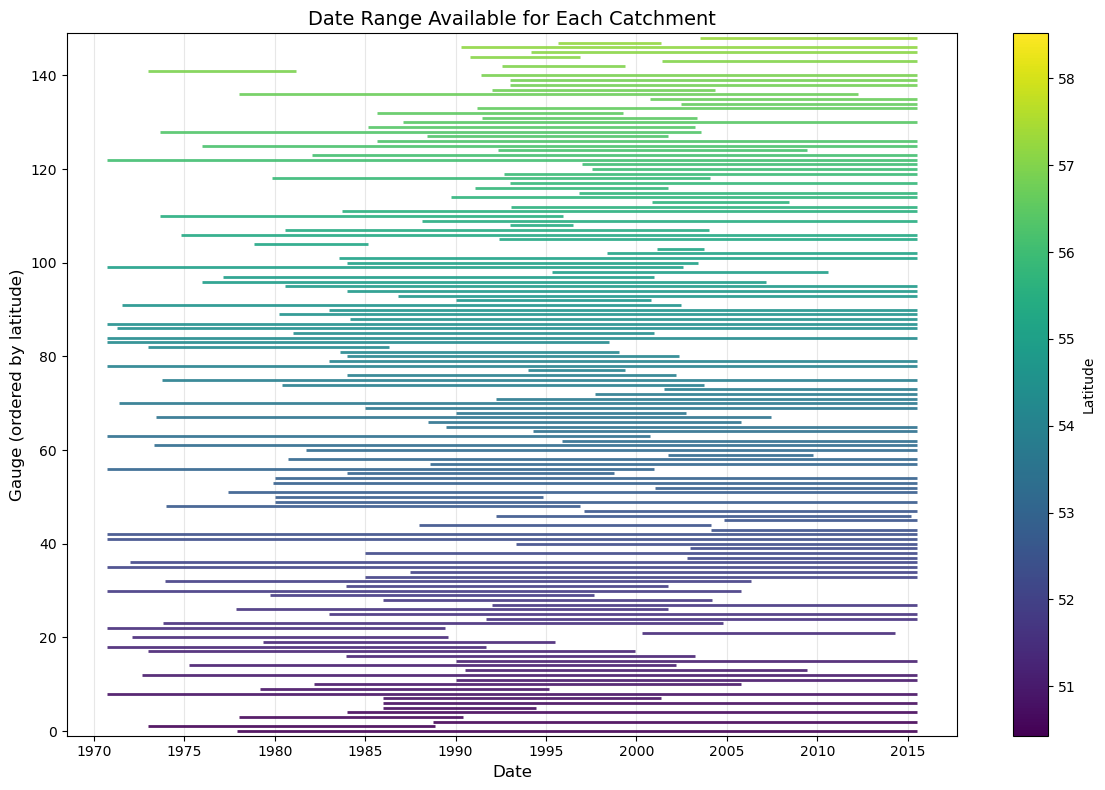

In [53]:
import matplotlib.pyplot as plt

# Sort by latitude
combined_summary_sorted = combined_summary.sort_values('gauge_lon', ascending=True)

# Convert dates to datetime if not already
combined_summary_sorted['first_init_date'] = pd.to_datetime(combined_summary_sorted['first_init_date'])
combined_summary_sorted['last_init_date'] = pd.to_datetime(combined_summary_sorted['last_init_date'])

# Create the plot
fig, ax = plt.subplots(figsize=(12, 8))

cmap = plt.cm.viridis
n_gauges = len(combined_summary_sorted)

# Plot horizontal lines with gradient colors
for i, row in enumerate(combined_summary_sorted.itertuples()):
    color = cmap(i / n_gauges  * 0.85)  # Normalize position to [0, 1]
    ax.plot([row.first_init_date, row.last_init_date], [i, i], 
            linewidth=2, solid_capstyle='butt', 
            color=color, alpha=0.9)

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Gauge (ordered by latitude)', fontsize=12)
ax.set_title('Date Range Available for Each Catchment', fontsize=14)
ax.set_ylim(-1, len(combined_summary_sorted))
ax.grid(True, alpha=0.3, axis='x')

# Add colorbar to show latitude mapping
sm = plt.cm.ScalarMappable(cmap=cmap, 
                            norm=plt.Normalize(vmin=combined_summary_sorted['gauge_lat'].min(), 
                                              vmax=combined_summary_sorted['gauge_lat'].max()))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Latitude')


plt.tight_layout()
plt.show()